CELL 1

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.read_csv(
    "models/final_v2/metrics_v2.csv"
)

results

,Model,Metric,Score
0,Category,Accuracy,1.0000
1,Complexity,Accuracy,0.6222
2,Priority,Accuracy,0.7517
3,Estimated Hours,MAE,2.2423
4,Estimated Hours,R2,0.7842
5,Required Skills,Micro F1,0.6637
6,Delay Risk,F1,0.7672
7,Delay Risk,Accuracy,0.8243


CELL 2 COMPARE WITH V1

In [2]:
baseline = {
    "Category": 0.998024,
    "Complexity": 0.196640,
    "Priority": 0.370553,
    "Required Skills": 0.517766,
    "Delay Risk": 0.633131
}

comparison = results[
    results["Model"].isin(baseline)
].copy()

comparison = comparison[
    ~comparison["Model"].duplicated()
]

comparison["V1 Score"] = (
    comparison["Model"].map(baseline)
)

comparison = comparison.rename(
    columns={"Score": "V2 Score"}
)

comparison

,Model,Metric,V2 Score,V1 Score
0,Category,Accuracy,1.0000,0.998024
1,Complexity,Accuracy,0.6222,0.196640
2,Priority,Accuracy,0.7517,0.370553
5,Required Skills,Micro F1,0.6637,0.517766
6,Delay Risk,F1,0.7672,0.633131


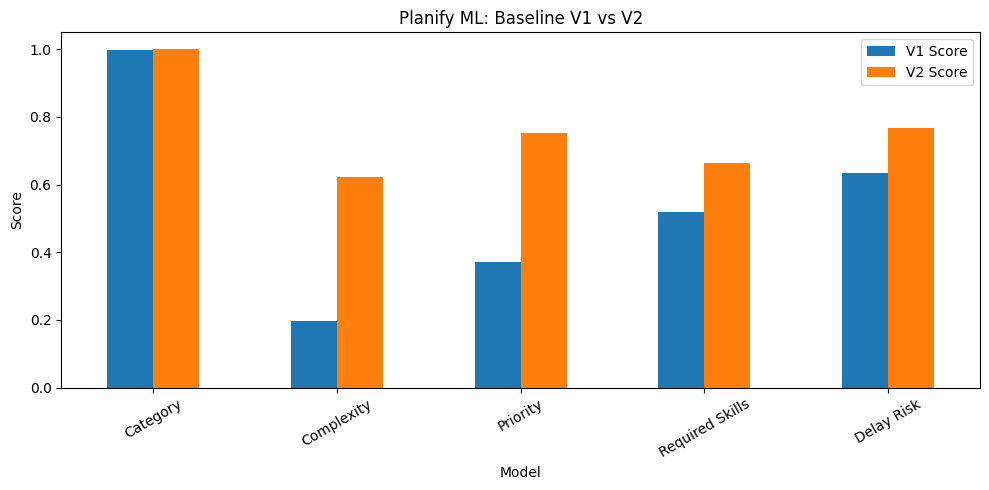

In [3]:
comparison.set_index("Model")[
    ["V1 Score", "V2 Score"]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Planify ML: Baseline V1 vs V2")
plt.ylabel("Score")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()